# 01 · Hospital Demand Forecasting
### Linear Regression for department-level patient demand

**Dataset:** `data/patient_flow.csv` — 9,216 patient-flow records covering Apr 2023 to Oct 2024.

**Goal:** estimate the expected number of patients arriving in each hospital department on a given date, then aggregate those estimates into a hospital-level resource plan.

**Workflow:** parse dates → build a date × department demand panel → engineer calendar features → time-based train/test split → Linear Regression → save model artifact and metadata.

> **Analytical note:** total daily arrivals are noisy in this extract (~16 patients/day, no strong trend or weekday effect). Department workload, however, is stable and predictable. The model therefore estimates demand at the **department-day level**, where it can support staffing decisions. Calendar features provide only a small adjustment; the department baseline carries most of the signal.
        

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.25})

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "patient_flow.csv"
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
print("Project root:", ROOT)
print("Using:", DATA_PATH)
        

Project root: C:\Users\Lenovo\health_analytics
Using: C:\Users\Lenovo\health_analytics\data\patient_flow.csv


## 1. Load and inspect the patient-flow data

In [2]:
flow = pd.read_csv(DATA_PATH)
print(f"Rows: {flow.shape[0]:,} | Columns: {flow.shape[1]}")
print("\nMissing values:")
print(flow.isna().sum().to_string())
print("\nColumn types:")
print(flow.dtypes.to_string())
flow.head()
        

Rows: 9,216 | Columns: 11

Missing values:
Patient Id                       0
Patient Admission Date           0
Patient Admission Time           0
Merged                           0
Patient Gender                   0
Patient Age                      0
Patient Race                     0
Department Referral           5400
Patient Admission Flag           0
Patient Satisfaction Score    6699
Patient Waittime                 0

Column types:
Patient Id                        str
Patient Admission Date            str
Patient Admission Time            str
Merged                            str
Patient Gender                    str
Patient Age                     int64
Patient Race                      str
Department Referral               str
Patient Admission Flag            str
Patient Satisfaction Score    float64
Patient Waittime                int64


,Patient Id,Patient Admission Date,Patient Admission Time,Merged,Patient Gender,Patient Age,Patient Race,Department Referral,Patient Admission Flag,Patient Satisfaction Score,Patient Waittime
0,780-96-6113,9/9/2024,9:25:00 AM,W. Breede,Female,63,African American,NaN,Not Admission,5.0,32
1,714-35-6722,9/9/2024,4:42:00 PM,Y. Baldetti,Male,31,Asian,Orthopedics,Not Admission,NaN,22
2,571-85-3714,9/9/2024,12:14:00 AM,M. Semerad,Male,75,White,General Practice,Not Admission,NaN,16
3,404-43-9499,9/9/2024,8:33:00 PM,K. Blaydes,Male,79,African American,General Practice,Admission,NaN,38
4,552-51-5855,9/9/2024,7:25:00 PM,F. Dickerson,Female,24,African American,NaN,Admission,NaN,36


## 2. Parse dates and operational fields

In [3]:
flow["admission_date"] = pd.to_datetime(
    flow["Patient Admission Date"], format="mixed", dayfirst=True
).dt.normalize()
flow["admission_time"] = pd.to_datetime(flow["Patient Admission Time"], format="%I:%M:%S %p")
flow["hour"] = flow["admission_time"].dt.hour
flow["admitted"] = (flow["Patient Admission Flag"] == "Admission").astype(int)
flow["department"] = flow["Department Referral"].fillna("No referral")
flow["date"] = flow["admission_date"]

print("Date range:", flow["date"].min().date(), "to", flow["date"].max().date())
print("Unique dates:", flow["date"].nunique())
print("Departments:", sorted(flow["department"].unique()))
print("Admission rate:", round(flow["admitted"].mean(), 3))
print("Average wait time:", round(flow["Patient Waittime"].mean(), 1), "minutes")
flow[["date", "hour", "department", "admitted", "Patient Waittime"]].head()
        

Date range: 2023-04-01 to 2024-10-30


Unique dates: 579
Departments: ['Cardiology', 'Gastroenterology', 'General Practice', 'Neurology', 'No referral', 'Orthopedics', 'Physiotherapy', 'Renal']
Admission rate: 0.5
Average wait time: 35.3 minutes


,date,hour,department,admitted,Patient Waittime
0,2024-09-09,9,No referral,0,32
1,2024-09-09,16,Orthopedics,0,22
2,2024-09-09,0,General Practice,0,16
3,2024-09-09,20,General Practice,1,38
4,2024-09-09,19,No referral,1,36


## 3. Explore total daily demand

In [4]:
daily = (
    flow.groupby("date")
    .agg(
        patients=("Patient Id", "count"),
        admissions=("admitted", "sum"),
        avg_wait_minutes=("Patient Waittime", "mean"),
        avg_age=("Patient Age", "mean"),
    )
    .reset_index()
    .sort_values("date")
)

full_dates = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
daily = (
    daily.set_index("date")
    .reindex(full_dates)
    .rename_axis("date")
    .reset_index()
)
daily["patients"] = daily["patients"].fillna(0).astype(int)
daily["admissions"] = daily["admissions"].fillna(0).astype(int)
daily["admission_rate"] = daily["admissions"] / daily["patients"].replace(0, np.nan)
daily["avg_wait_minutes"] = daily["avg_wait_minutes"].interpolate()
daily["avg_age"] = daily["avg_age"].interpolate()
daily["patients_7d"] = daily["patients"].rolling(7, min_periods=1).mean()

print("Days:", len(daily))
daily[["patients", "admissions", "avg_wait_minutes"]].describe().round(2)
        

Days: 579


,patients,admissions,avg_wait_minutes
count,579.00,579.00,579.00
mean,15.92,7.97,35.22
std,3.73,2.67,3.87
min,7.00,1.00,24.50
25%,13.00,6.00,32.58
50%,16.00,8.00,35.05
75%,18.00,10.00,37.82
max,30.00,17.00,45.47


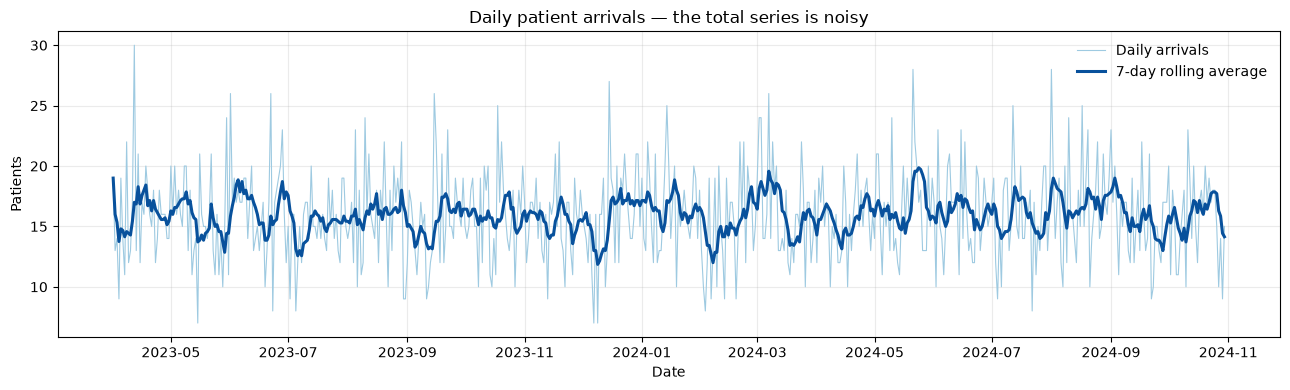

In [5]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily["date"], daily["patients"], color="#9ecae1", linewidth=0.8, label="Daily arrivals")
ax.plot(daily["date"], daily["patients_7d"], color="#08519c", linewidth=2.2, label="7-day rolling average")
ax.set_title("Daily patient arrivals — the total series is noisy")
ax.set_xlabel("Date")
ax.set_ylabel("Patients")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
        

## 4. Build the date × department demand panel

In [6]:
departments = sorted(flow["department"].unique())
panel_index = pd.MultiIndex.from_product(
    [full_dates, departments], names=["date", "department"]
)

panel = (
    flow.groupby(["date", "department"])
    .agg(
        patients=("Patient Id", "count"),
        admissions=("admitted", "sum"),
    )
    .reindex(panel_index, fill_value=0)
    .reset_index()
)
panel["weekday"] = panel["date"].dt.day_name()
panel["month"] = panel["date"].dt.month_name()
panel["is_weekend"] = (panel["date"].dt.dayofweek >= 5).astype(int)

print(f"Panel rows: {len(panel):,} = {len(full_dates)} days × {len(departments)} departments")
panel.groupby("department")[["patients", "admissions"]].mean().round(2).sort_values("patients", ascending=False)
        

Panel rows: 4,632 = 579 days × 8 departments


,patients,admissions
department,,
No referral,9.33,4.73
General Practice,3.18,1.53
Orthopedics,1.72,0.86
Physiotherapy,0.48,0.24
Cardiology,0.43,0.21
Neurology,0.33,0.17
Gastroenterology,0.31,0.15
Renal,0.15,0.08


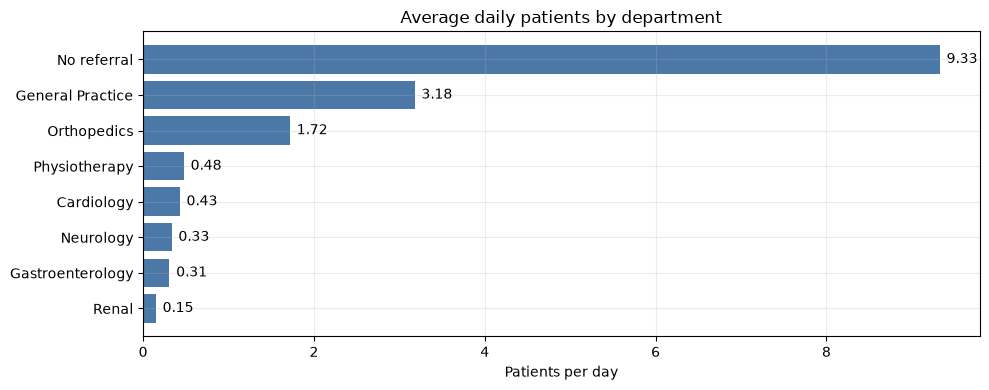

In [7]:
dept_means = panel.groupby("department")["patients"].mean().sort_values()

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(dept_means.index, dept_means.values, color="#4c78a8")
ax.set_title("Average daily patients by department")
ax.set_xlabel("Patients per day")
for i, value in enumerate(dept_means.values):
    ax.text(value + 0.08, i, f"{value:.2f}", va="center")
plt.tight_layout()
plt.show()
        

## 5. Train / test split and Linear Regression

In [8]:
features = ["department", "weekday", "month", "is_weekend"]
split_date = full_dates[int(len(full_dates) * 0.80)]
train = panel[panel["date"] < split_date].copy()
test = panel[panel["date"] >= split_date].copy()

X_train, y_train = train[features], train["patients"]
X_test, y_test = test[features], test["patients"]

print(f"Train: {train['date'].min().date()} to {train['date'].max().date()} ({train['date'].nunique()} days)")
print(f"Test:  {test['date'].min().date()} to {test['date'].max().date()} ({test['date'].nunique()} days)")
print(f"Train rows: {len(train):,} | Test rows: {len(test):,}")
        

Train: 2023-04-01 to 2024-07-06 (463 days)
Test:  2024-07-07 to 2024-10-30 (116 days)
Train rows: 3,704 | Test rows: 928


In [9]:
preprocessor = ColumnTransformer(
    [
        (
            "department",
            OneHotEncoder(handle_unknown="ignore", drop="first"),
            ["department"],
        ),
        (
            "calendar",
            OneHotEncoder(handle_unknown="ignore", drop="first"),
            ["weekday", "month"],
        ),
    ],
    remainder="passthrough",
)

demand_model = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression()),
    ]
)
demand_model.fit(X_train, y_train)
print("Model fitted.")
        

Model fitted.


## 6. Evaluate at department-day and daily-total level

In [10]:
test["prediction"] = np.clip(demand_model.predict(X_test), 0, None)
department_baseline = train.groupby("department")["patients"].mean()
global_baseline = train["patients"].mean()
test["department_baseline"] = test["department"].map(department_baseline)

department_metrics = pd.Series(
    {
        "MAE": mean_absolute_error(y_test, test["prediction"]),
        "RMSE": np.sqrt(mean_squared_error(y_test, test["prediction"])),
        "R²": r2_score(y_test, test["prediction"]),
        "Department-mean baseline MAE": mean_absolute_error(y_test, test["department_baseline"]),
        "Global-mean baseline MAE": mean_absolute_error(y_test, np.full(len(y_test), global_baseline)),
    }
).round(3)

print("Department-day level")
department_metrics.to_frame("value")
        

Department-day level


,value
MAE,0.898
RMSE,1.395
R²,0.817
Department-mean baseline MAE,0.911
Global-mean baseline MAE,2.292


In [11]:
daily_test = (
    test.groupby("date")[["patients", "prediction", "department_baseline"]]
    .sum()
    .rename(columns={"patients": "actual", "prediction": "predicted"})
)
daily_metrics = pd.Series(
    {
        "MAE": mean_absolute_error(daily_test["actual"], daily_test["predicted"]),
        "RMSE": np.sqrt(mean_squared_error(daily_test["actual"], daily_test["predicted"])),
        "R²": r2_score(daily_test["actual"], daily_test["predicted"]),
        "Baseline MAE": mean_absolute_error(daily_test["actual"], daily_test["department_baseline"]),
    }
).round(3)
print("Daily-total level (sum of department predictions)")
daily_metrics.to_frame("value")
        

Daily-total level (sum of department predictions)


,value
MAE,2.941
RMSE,3.749
R²,-0.013
Baseline MAE,2.939


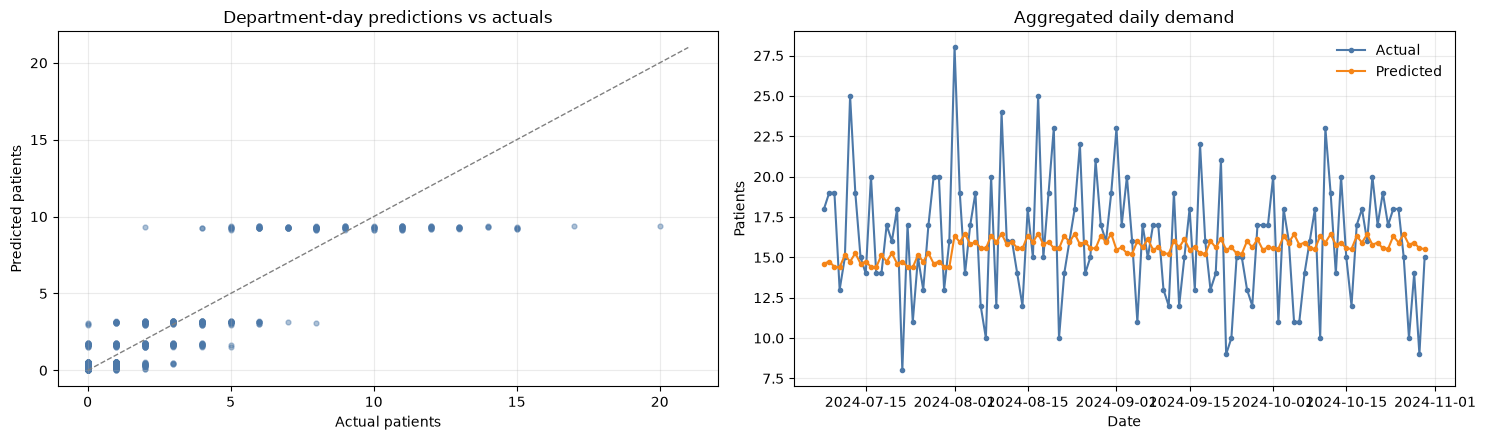

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].scatter(test["patients"], test["prediction"], s=12, alpha=0.45, color="#4c78a8")
limit = max(test["patients"].max(), test["prediction"].max()) + 1
axes[0].plot([0, limit], [0, limit], "--", color="grey", linewidth=1)
axes[0].set_title("Department-day predictions vs actuals")
axes[0].set_xlabel("Actual patients")
axes[0].set_ylabel("Predicted patients")

axes[1].plot(daily_test.index, daily_test["actual"], marker="o", markersize=3, label="Actual", color="#4c78a8")
axes[1].plot(daily_test.index, daily_test["predicted"], marker="o", markersize=3, label="Predicted", color="#f58518")
axes[1].set_title("Aggregated daily demand")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Patients")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()
        

The model explains department-level workload very well, but the aggregated daily total is still dominated by random day-to-day variation. That is an important operational finding: **planning should be department-aware**, and the total forecast should be presented with a wide planning interval rather than as a precise number.
        

In [13]:
residual_std = float(np.std(y_test - test["prediction"], ddof=1))
daily_total_residual_std = float(np.std(daily_test["actual"] - daily_test["predicted"], ddof=1))

print(f"Department-day residual standard deviation: {residual_std:.2f} patients")
print(f"Daily-total residual standard deviation: {daily_total_residual_std:.2f} patients")
print(f"Average actual daily demand in test period: {daily_test['actual'].mean():.1f} patients/day")
        

Department-day residual standard deviation: 1.39 patients
Daily-total residual standard deviation: 3.72 patients
Average actual daily demand in test period: 16.1 patients/day


### What the linear model learned

In [14]:
feature_names = demand_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.DataFrame(
    {
        "feature": [name.split("__", 1)[-1] for name in feature_names],
        "coefficient": demand_model.named_steps["regressor"].coef_,
    }
)
coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()
coefficients.sort_values("absolute_coefficient", ascending=False).head(15).round(3)
        

,feature,coefficient,absolute_coefficient
3,department_No referral,8.881,8.881
1,department_General Practice,2.715,2.715
4,department_Orthopedics,1.259,1.259
6,department_Renal,-0.289,0.289
0,department_Gastroenterology,-0.134,0.134
17,month_July,-0.132,0.132
15,month_February,-0.119,0.119
2,department_Neurology,-0.119,0.119
16,month_January,0.097,0.097
18,month_June,0.088,0.088


## 7. Save the model and metadata

In [15]:
joblib.dump(demand_model, MODEL_DIR / "demand_linear.joblib")

history = daily[["date", "patients", "admissions"]].copy()
history["date"] = history["date"].dt.strftime("%Y-%m-%d")

department_shares = flow["department"].value_counts(normalize=True).round(4).to_dict()
department_daily_mean = (
    panel.groupby("department")["patients"].mean().round(3).to_dict()
)
weekday_demand = (
    daily.assign(weekday=daily["date"].dt.day_name())
    .groupby("weekday")["patients"].mean()
    .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
)
month_order = list(pd.date_range("2024-01-01", periods=12, freq="MS").strftime("%B"))
month_demand = (
    daily.assign(month=daily["date"].dt.month_name())
    .groupby("month")["patients"].mean()
    .reindex(month_order)
)

demand_meta = {
    "target": "patients per department-day",
    "model": "LinearRegression",
    "features": features,
    "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    "data_start": str(daily["date"].min().date()),
    "data_end": str(daily["date"].max().date()),
    "n_days": int(len(daily)),
    "train_days": int(train["date"].nunique()),
    "test_days": int(test["date"].nunique()),
    "train_start": str(train["date"].min().date()),
    "train_end": str(train["date"].max().date()),
    "test_start": str(test["date"].min().date()),
    "test_end": str(test["date"].max().date()),
    "departments": departments,
    "metrics": {
        "department_day": {k: float(v) for k, v in department_metrics.items()},
        "daily_total": {k: float(v) for k, v in daily_metrics.items()},
    },
    "residual_std": residual_std,
    "daily_total_residual_std": daily_total_residual_std,
    "mean_daily_demand": float(daily["patients"].mean()),
    "admission_rate": float(flow["admitted"].mean()),
    "avg_wait_minutes": float(flow["Patient Waittime"].mean()),
    "department_shares": {k: float(v) for k, v in department_shares.items()},
    "department_daily_mean": {k: float(v) for k, v in department_daily_mean.items()},
    "weekday_demand": {str(k): float(v) for k, v in weekday_demand.items()},
    "month_demand": {str(k): float(v) for k, v in month_demand.items()},
    "resource_assumptions": {
        "bed_buffer": 1.15,
        "patients_per_doctor": 8,
        "patients_per_nurse": 4,
        "patients_per_support": 10,
        "exam_rooms_per_patient": 0.15,
    },
    "history": history.to_dict(orient="records"),
    "interpretation": (
        "Department baseline explains most of the explainable variance. "
        "Calendar features add a small adjustment; aggregate daily totals remain noisy."
    ),
}

with open(MODEL_DIR / "demand_meta.json", "w", encoding="utf-8") as f:
    json.dump(demand_meta, f, indent=2)

print("Saved:")
print(" -", MODEL_DIR / "demand_linear.joblib")
print(" -", MODEL_DIR / "demand_meta.json")
        

Saved:
 - C:\Users\Lenovo\health_analytics\models\demand_linear.joblib
 - C:\Users\Lenovo\health_analytics\models\demand_meta.json


### Result

- The model estimates expected patient volume for each department on a given date.
- Department-level R² is strong because baseline workload varies substantially across departments.
- The API can aggregate department estimates into a hospital total and show the department mix behind the resource plan.
- The daily-total interval is wide because day-to-day variation in this extract is mostly noise — the dashboard reports that uncertainty explicitly.
- **Artifacts:** `models/demand_linear.joblib`, `models/demand_meta.json`.
        